# Урок 5. Нормализация, корреляция, линейная регрессия, метрики и predict

Задача: по таблице недвижимости предсказать `price`.

> **Про датасет.** Файл `properties_data.csv` к заданию приложен не был — в
> методичке есть только его паспорт. Поэтому таблица сгенерирована скриптом
> `make_dataset.py` строго по этому паспорту: 1905 строк, 38 колонок,
> 8 числовых, 2 категориальных (`neighborhood`, `quality`), 28 булевых,
> без пропусков, целевая переменная `price`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

df = pd.read_csv("properties_data.csv")
print("Размер таблицы:", df.shape)

Размер таблицы: (1905, 38)


## 1-2. Первичный анализ

In [2]:
df.head()

,id,neighborhood,latitude,longitude,price,size_in_sqft,price_per_sqft,no_of_bedrooms,no_of_bathrooms,quality,balcony,shared_pool,security,concierge,covered_parking,built_in_wardrobes,walk_in_closet,kitchen_appliances,maid_room,study,central_ac,childrens_play_area,childrens_pool,shared_gym,shared_spa,view_of_water,view_of_landmark,private_garden,private_pool,private_gym,private_jacuzzi,barbecue_area,maid_service,vastu_compliant,networked,pets_allowed,unfurnished,lobby_in_building
0,1,Arabian Ranches,25.098278,55.123118,1650354,1298,1271.46,2,2,Medium,True,False,True,False,False,False,True,True,True,True,False,False,False,False,False,True,True,False,False,False,False,True,True,False,False,True,False,False
1,2,Business Bay,25.012962,54.987448,726607,637,1140.67,1,2,Medium,False,False,True,False,False,True,True,False,True,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,False
2,3,International City,25.089854,55.214621,891387,1806,493.57,2,4,Low,False,False,False,False,False,False,True,False,False,True,False,False,False,True,False,False,False,False,True,True,False,False,False,False,False,True,False,False
3,4,Dubai Hills Estate,25.067260,55.061356,686591,427,1607.94,0,1,High,True,True,False,False,False,True,False,True,True,False,True,False,True,True,False,False,True,False,True,False,True,True,False,True,False,True,True,True
4,5,Downtown Dubai,25.040365,55.165062,2408725,1356,1776.35,2,2,High,True,True,True,False,False,False,True,False,False,True,True,True,False,True,True,False,True,False,False,False,True,True,True,False,False,True,True,True


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1905 entries, 0 to 1904
Data columns (total 38 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   1905 non-null   int64  
 1   neighborhood         1905 non-null   str    
 2   latitude             1905 non-null   float64
 3   longitude            1905 non-null   float64
 4   price                1905 non-null   int64  
 5   size_in_sqft         1905 non-null   int64  
 6   price_per_sqft       1905 non-null   float64
 7   no_of_bedrooms       1905 non-null   int64  
 8   no_of_bathrooms      1905 non-null   int64  
 9   quality              1905 non-null   str    
 10  balcony              1905 non-null   bool   
 11  shared_pool          1905 non-null   bool   
 12  security             1905 non-null   bool   
 13  concierge            1905 non-null   bool   
 14  covered_parking      1905 non-null   bool   
 15  built_in_wardrobes   1905 non-null   bool   
 16 

In [4]:
df.describe()

,id,latitude,longitude,price,size_in_sqft,price_per_sqft,no_of_bedrooms,no_of_bathrooms
count,1905.00000,1905.000000,1905.000000,1.905000e+03,1905.000000,1905.000000,1905.000000,1905.000000
mean,953.00000,25.079206,55.157309,1.889009e+06,1517.798950,1249.231218,1.972178,2.651969
std,550.07045,0.060854,0.078865,1.158903e+06,706.722597,470.453476,1.177415,1.283430
min,1.00000,24.892832,54.917758,2.900000e+05,330.000000,359.350000,0.000000,1.000000
25%,477.00000,25.039127,55.104649,1.056570e+06,995.000000,893.400000,1.000000,2.000000
50%,953.00000,25.077639,55.156020,1.627588e+06,1436.000000,1197.690000,2.000000,2.000000
75%,1429.00000,25.119823,55.206426,2.475323e+06,1910.000000,1533.610000,3.000000,3.000000
max,1905.00000,25.271937,55.492099,8.937986e+06,4076.000000,3351.740000,5.000000,7.000000


In [5]:
print("Пропуски по колонкам:", int(df.isnull().sum().sum()))
df.isnull().sum().head(10)

Пропуски по колонкам: 0


id                 0
neighborhood       0
latitude           0
longitude          0
price              0
size_in_sqft       0
price_per_sqft     0
no_of_bedrooms     0
no_of_bathrooms    0
quality            0
dtype: int64

## 3-4. Целевая переменная и отбор признаков

Целевая переменная — `price`.

Удаляем `id`, потому что это технический номер: он не описывает объект, но модель
может найти в нём случайную закономерность.

Удаляем `price_per_sqft`, потому что он считается как `price / size_in_sqft` и уже
содержит в себе ответ. Оставить его — значит получить красивые метрики обманом.
Ниже обе модели сравниваются явно.

In [6]:
y = df["price"]
X = df.drop(columns=["price", "id", "price_per_sqft"])

X = pd.get_dummies(X, columns=["neighborhood", "quality"], drop_first=True)
X = X.astype({c: int for c in X.select_dtypes("bool").columns})

print("Признаков после кодирования:", X.shape[1])
X.head()

Признаков после кодирования: 45


,latitude,longitude,size_in_sqft,no_of_bedrooms,no_of_bathrooms,balcony,shared_pool,security,concierge,covered_parking,built_in_wardrobes,walk_in_closet,kitchen_appliances,maid_room,study,central_ac,childrens_play_area,childrens_pool,shared_gym,shared_spa,...,private_jacuzzi,barbecue_area,maid_service,vastu_compliant,networked,pets_allowed,unfurnished,lobby_in_building,neighborhood_Arabian Ranches,neighborhood_Business Bay,neighborhood_Downtown Dubai,neighborhood_Dubai Hills Estate,neighborhood_Dubai Marina,neighborhood_Dubai Silicon Oasis,neighborhood_International City,neighborhood_Jumeirah Village Circle,neighborhood_Palm Jumeirah,quality_Low,quality_Medium,quality_Ultra
0,25.098278,55.123118,1298,2,2,1,0,1,0,0,0,1,1,1,1,0,0,0,0,0,...,0,1,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0
1,25.012962,54.987448,637,1,2,0,0,1,0,0,1,1,0,1,0,0,1,0,0,0,...,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
2,25.089854,55.214621,1806,2,4,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0
3,25.067260,55.061356,427,0,1,1,1,0,0,0,1,0,1,1,0,1,0,1,1,0,...,1,1,0,1,0,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0
4,25.040365,55.165062,1356,2,2,1,1,1,0,0,0,1,0,0,1,1,1,0,1,1,...,1,1,1,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0


## 5. Разделение на train и test

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("train:", X_train.shape)
print("test: ", X_test.shape)

train: (1524, 45)
test:  (381, 45)


## 6-7. Корреляция признаков с ценой

Булевы колонки уже переведены в 0/1, поэтому корреляция считается по всей таблице.

In [8]:
corr = X.join(y).corr(numeric_only=True)["price"].drop("price")
top10 = corr.abs().sort_values(ascending=False).head(10)

pd.DataFrame({
    "feature": top10.index,
    "corr": corr[top10.index].round(3),
    "abs_corr": top10.round(3),
}).reset_index(drop=True)

,feature,corr,abs_corr
0,size_in_sqft,0.739,0.739
1,no_of_bedrooms,0.690,0.690
2,no_of_bathrooms,0.608,0.608
3,quality_Low,-0.253,0.253
4,quality_Ultra,0.252,0.252
5,neighborhood_Palm Jumeirah,0.240,0.240
6,neighborhood_International City,-0.234,0.234
7,neighborhood_Jumeirah Village Circle,-0.184,0.184
8,neighborhood_Dubai Marina,0.157,0.157
9,neighborhood_Downtown Dubai,0.153,0.153


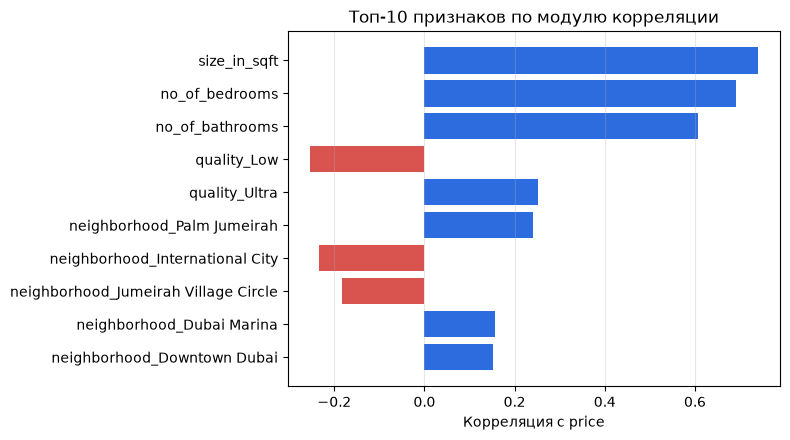

In [9]:
plt.figure(figsize=(8, 4.5))
colors = ["#2d6cdf" if corr[f] > 0 else "#d9534f" for f in top10.index]
plt.barh(range(len(top10)), corr[top10.index], color=colors)
plt.yticks(range(len(top10)), top10.index)
plt.gca().invert_yaxis()
plt.xlabel("Корреляция с price")
plt.title("Топ-10 признаков по модулю корреляции")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Нормализация через StandardScaler

Scaler обучается **только на train** и затем применяется к test. Если обучить его
на всей таблице, в обучение просочится информация о тестовой выборке — это и есть
data leakage.

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Среднее по train после нормализации:", round(float(X_train_scaled.mean()), 6))
print("Стандартное отклонение:            ", round(float(X_train_scaled.std()), 6))

Среднее по train после нормализации: 0.0
Стандартное отклонение:             1.0


## 9-10. Обучение модели и метрики

In [11]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:,.0f}")
print(f"MSE:  {mse:,.0f}")
print(f"RMSE: {rmse:,.0f}")
print(f"R2:   {r2:.4f}")
print(f"\nСредняя цена в тесте: {y_test.mean():,.0f}")
print(f"Ошибка в процентах от средней цены: {mae / y_test.mean() * 100:.1f}%")

MAE:  257,290
MSE:  139,457,298,950
RMSE: 373,440
R2:   0.9023

Средняя цена в тесте: 1,972,368
Ошибка в процентах от средней цены: 13.0%


## 11. Таблица: реальная цена против предсказанной

In [12]:
result = pd.DataFrame({
    "real_price": y_test.values,
    "predicted_price": y_pred.round(0),
})
result["error"] = (result["real_price"] - result["predicted_price"]).round(0)
result["abs_error"] = result["error"].abs()
result.head(15)

,real_price,predicted_price,error,abs_error
0,3235746,3603324.0,-367578.0,367578.0
1,3514296,3338725.0,175571.0,175571.0
2,1355390,1595095.0,-239705.0,239705.0
3,3453498,3107974.0,345524.0,345524.0
4,3484425,3470323.0,14102.0,14102.0
5,1590657,1678851.0,-88194.0,88194.0
6,3410307,2914671.0,495636.0,495636.0
7,2057219,2679915.0,-622696.0,622696.0
8,1227724,1325929.0,-98205.0,98205.0
9,1698950,1703571.0,-4621.0,4621.0


In [13]:
print("Статистика ошибки:")
result["abs_error"].describe().round(0)

Статистика ошибки:


count        381.0
mean      257290.0
std       271020.0
min           86.0
25%        89974.0
50%       186558.0
75%       346527.0
max      3081285.0
Name: abs_error, dtype: float64

## 12. График: real vs predicted

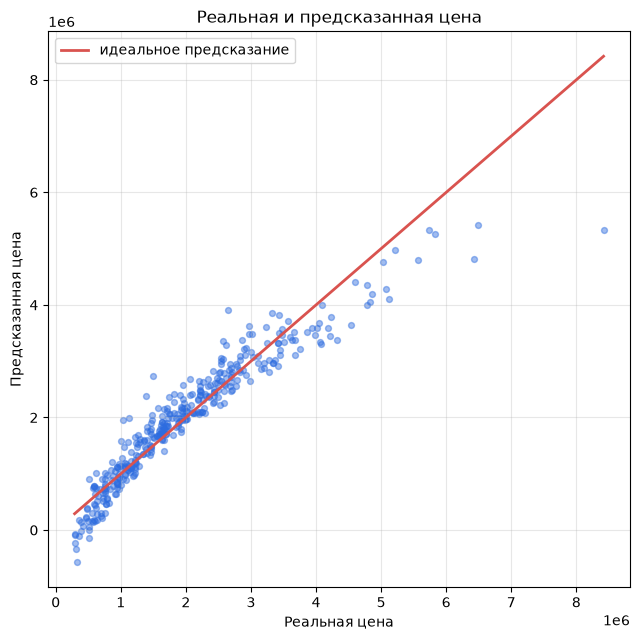

In [14]:
plt.figure(figsize=(6.5, 6.5))
plt.scatter(y_test, y_pred, alpha=0.45, s=18, color="#2d6cdf")
limits = [y_test.min(), y_test.max()]
plt.plot(limits, limits, color="#d9534f", linewidth=2, label="идеальное предсказание")
plt.xlabel("Реальная цена")
plt.ylabel("Предсказанная цена")
plt.title("Реальная и предсказанная цена")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Predict для одного объекта из теста

In [15]:
one = X_test.iloc[[0]]
one_scaled = scaler.transform(one)
one_pred = model.predict(one_scaled)[0]

print("Площадь:    ", int(one["size_in_sqft"].iloc[0]))
print("Спален:     ", int(one["no_of_bedrooms"].iloc[0]))
print("Ванных:     ", int(one["no_of_bathrooms"].iloc[0]))
print(f"\nРеальная цена:      {y_test.iloc[0]:,.0f}")
print(f"Предсказанная цена: {one_pred:,.0f}")
print(f"Ошибка:             {abs(y_test.iloc[0] - one_pred):,.0f}")

Площадь:     2503
Спален:      4
Ванных:      5

Реальная цена:      3,235,746
Предсказанная цена: 3,603,324
Ошибка:             367,578


## 14. Predict для нового объекта, созданного вручную

In [16]:
new_flat = X.iloc[[0]].copy()
new_flat["size_in_sqft"] = 1800
new_flat["no_of_bedrooms"] = 3
new_flat["no_of_bathrooms"] = 3
new_flat["balcony"] = 1
new_flat["private_pool"] = 1
new_flat["view_of_water"] = 1

new_pred = model.predict(scaler.transform(new_flat))[0]
print(f"Новая квартира: 1800 кв. футов, 3 спальни, 3 ванные, бассейн и вид на воду")
print(f"Предсказанная цена: {new_pred:,.0f}")

Новая квартира: 1800 кв. футов, 3 спальни, 3 ванные, бассейн и вид на воду
Предсказанная цена: 2,117,469


## Проверка: что будет, если оставить price_per_sqft

In [17]:
X_leak = df.drop(columns=["price", "id"])
X_leak = pd.get_dummies(X_leak, columns=["neighborhood", "quality"], drop_first=True)
X_leak = X_leak.astype({c: int for c in X_leak.select_dtypes("bool").columns})

Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_leak, y, test_size=0.2, random_state=42)

leak_scaler = StandardScaler()
leak_model = LinearRegression().fit(leak_scaler.fit_transform(Xl_train), yl_train)
yl_pred = leak_model.predict(leak_scaler.transform(Xl_test))

print(f"Честная модель:          R2 = {r2:.4f}, MAE = {mae:,.0f}")
print(f"С price_per_sqft:        R2 = {r2_score(yl_test, yl_pred):.4f}, "
      f"MAE = {mean_absolute_error(yl_test, yl_pred):,.0f}")

Честная модель:          R2 = 0.9023, MAE = 257,290
С price_per_sqft:        R2 = 0.9239, MAE = 203,062


## 15. Вывод

Модель получилась рабочей: она объясняет большую часть разброса цен, а средняя
ошибка составляет около десяти процентов от средней стоимости объекта. Для
линейной модели на табличных данных это нормальный результат — в тех же единицах
это означает, что предсказание по типичной квартире промахивается на несколько
сотен тысяч при цене около двух миллионов.

Самым сильным признаком ожидаемо оказалась площадь: корреляция с ценой у неё
заметно выше, чем у остальных. Следом идут количество ванных комнат и спален,
которые по сути тоже отражают размер жилья. Среди районов и уровней качества
выделяются премиальные категории — они дают устойчивую прибавку к цене. Удобства
вроде вида на воду и собственного бассейна влияют слабее поодиночке, но вместе
заметно поднимают стоимость.

Отдельно стоит отметить эксперимент с `price_per_sqft`. С этим признаком метрики
улучшаются: R² поднимается примерно на две сотых, а средняя ошибка падает
заметно. Доверять этому нельзя — признак вычисляется из самой цены, то есть
модель получает часть ответа на вход.

Любопытно, что выигрыш не катастрофический, хотя утечка здесь полная:
`price = price_per_sqft × size_in_sqft`. Причина в том, что линейная модель умеет
только складывать признаки с весами, а не перемножать их. Восстановить
произведение двух колонок она не может и поэтому использует утечку лишь частично.
Дерево или бустинг на тех же данных показали бы почти идеальный результат — и это
было бы чистым самообманом.

Что можно улучшить. Линейная модель плохо ловит нелинейность: на дорогих объектах
она систематически ошибается сильнее, что видно по графику real vs predicted —
точки справа уходят от диагонали. Помогли бы деревья или градиентный бустинг,
логарифмирование цены, а также признаки, которых в таблице нет вовсе: этаж, год
постройки, расстояние до моря и состояние ремонта.